# LM6 Lab — Sequences, Series and the Time Value of Money

Companion notebook to **From Calculus to Kelly, LM6**. It rebuilds every exhibit and computational example of the module from the data in `data/` and solves the computational practice problems.

| Part | Rebuilds |
|:--|:--|
| 1 | Geometric series and annuities (Example 1, Example 2) |
| 2 | Gordon growth model on 0050 from raw prices and dividends (Exhibit 3, Example 3, Example 4) |
| 3 | Bond pricing, bisection for yield to maturity and IRR, pull to par (Example 5, Exhibit 4, Example 6, Exhibit 5) |
| 4 | Loan amortization: level payment, equal principal, grace period (Example 7, Exhibit 6) |
| 5 | Implied forward rates and covered interest parity (Exhibit 7, Example 8) |
| 6 | The TX basis through the 2025 dividend season (Exhibit 1, Exhibit 8, Exhibit 9, Exhibit 10, Exhibit 11, Exhibit 12, Example 9) |
| 7 | Practice-problem solutions and an extension exercise |

**Environment.** From the repository root, `uv sync` installs the locked Python environment (`uv.lock`). Open this notebook with the `.venv` kernel, or run `uv run --with jupyterlab jupyter lab`.

**Data** (`data/`, FinMind, as retrieved 2026-10-10): TX regular-session settlements and volumes `TaiwanFuturesDaily` (2025-04-01 → 2025-10-31), TAIEX closes `TaiwanStockPrice` and the TWSE total-return index `TaiwanStockTotalReturnIndex` for calendar 2025, TAIEX high/low around 27 June 2025, 0050 daily closes 2014-10-31 → 2026-10-09 and cash dividends `TaiwanStockDividendResult`. The notebook reads FinMind files that you download once with your own token. From the repository root, run `uv run python data/fetch_finmind.py`, then `uv run python data/make_lab_data.py`. FinMind's licence does not allow the book to redistribute the data. After that, the notebook runs offline.

**Conventions (as in the module).** $\mathrm{PMT}$ is a level payment, $\gamma$ a simple growth rate per period, $M$ a face value, $B_t$ an account or loan balance after $t$ periods (LM6 has no Brownian motion). Time to expiry $\tau=$ calendar days ÷ 365 (actual/365, as DBS Taiwan accrues NTD deposits; see LM1); the financing-rate proxy is $r_f=2\%$ (continuously compounded), the central bank's discount rate throughout 2025. TAIEX closes on a 13:25–13:30 call auction while the TX daily settlement is the volume-weighted price of the last minute before 13:45, so the daily basis is noisy; beyond the second month, contracts trade a few dozen lots a day or fewer.

In [1]:
from pathlib import Path
import datetime as dt
import math
import numpy as np
import polars as pl
import matplotlib.pyplot as plt

DATA = Path("data")
pl.Config.set_tbl_rows(40)
pl.Config.set_tbl_cols(12)
pl.Config.set_float_precision(4)
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

## Part 1 — Geometric series and annuities

Everything rests on (6.2): $\sum_{j=0}^{n-1}a_1x^j=a_1(1-x^n)/(1-x)$, and on (6.3) for $|x|<1$. With $v=1/(1+i)$ the annuity factors follow: $a_{n,i}=(1-v^n)/i$ (6.5), $s_{n,i}=((1+i)^n-1)/i$ (6.6), and an annuity due is worth $1+i$ times as much (6.7).

In [2]:
def geo_sum(a1, x, n):
    return n * a1 if x == 1 else a1 * (1 - x**n) / (1 - x)             # eq. (6.2)

def annuity_pv(pmt, i, n, due=False):
    pv = pmt * n if i == 0 else pmt * (1 - (1 + i) ** -n) / i          # eq. (6.5)
    return pv * (1 + i) if due else pv                                 # eq. (6.7)

def annuity_fv(pmt, i, n, due=False):
    fv = pmt * n if i == 0 else pmt * ((1 + i) ** n - 1) / i           # eq. (6.6)
    return fv * (1 + i) if due else fv

def growing_annuity_pv(pmt1, i, gamma, n):
    if abs(i - gamma) < 1e-15:
        return n * pmt1 / (1 + i)
    return pmt1 / (i - gamma) * (1 - ((1 + gamma) / (1 + i)) ** n)     # eq. (6.9)

def bisect(fn, lo, hi, tol=1e-10, log=None):
    # each pass halves the bracket [lo, hi]; log rows are (step, lo, hi, midpoint, fn(midpoint))
    f_lo = fn(lo)
    if f_lo * fn(hi) > 0:
        raise ValueError("root not bracketed")
    step = 0
    while True:
        step += 1
        mid = 0.5 * (lo + hi); f_mid = fn(mid)
        if log is not None: log.append((step, lo, hi, mid, f_mid))
        if f_mid == 0 or (hi - lo) / 2 < tol: return mid, step
        if f_lo * f_mid < 0: hi = mid
        else: lo, f_lo = mid, f_mid

# Example 1: share of a perpetuity paid within n years, 1 - v^n
tail = pl.DataFrame({"rate": [0.02, 0.05, 0.08]}).with_columns(
    (1 / pl.col("rate")).alias("value of 1/yr forever"),
    *[(1 - (1 + pl.col("rate")) ** -n).alias(f"within {n}y") for n in (10, 30, 50)])
tail

rate,value of 1/yr forever,within 10y,within 30y,within 50y
f64,f64,f64,f64,f64
0.0200,50.0000,0.1797,0.4479,0.6285
0.0500,20.0000,0.3861,0.7686,0.9128
0.0800,12.5000,0.5368,0.9006,0.9787


In [3]:
# Knowledge check (Section 2) and the sum in Practice Problem 1
print("52-week challenge:", sum(100 * j for j in range(1, 53)), "| 95% forever from 100:", round(100 / (1 - 0.95), 2))
print("PP1: sum 0.9^j, j<20 =", round(geo_sum(1, 0.9, 20), 4), "| infinite sum:", round(1 / (1 - 0.9), 4), "| 20 terms that do not shrink: 20")

# Example 2 (a): monthly deposit for NT$3,000,000 in 8 years at 0.2% a month; (b) how long NT$10m lasts at 0.25%
i, n = 0.002, 96
pmt = 3_000_000 * i / ((1 + i) ** n - 1)
print(f"(a) deposit {pmt:,.2f}  total {pmt*n:,.0f}  interest {3_000_000-pmt*n:,.0f}  as annuity due {pmt/(1+i):,.2f}")
nmon = -math.log(1 - 10_000_000 * 0.0025 / 60_000) / math.log(1.0025)
print(f"(b) lasts {nmon:.2f} months = {nmon/12:.2f} years;  perpetual withdrawal {10_000_000*0.0025:,.0f}")

# Knowledge check (Section 3)
print("KC3:", [round(f(1000, 0.03, 10, d), 2) for f in (annuity_pv, annuity_fv) for d in (False, True)])
# Section 4 checks: perpetuity, deferred perpetuity, growing annuity
print("perpetuity 2.4/4%:", 2.4 / 0.04, " deferred m=5:", round(2.4 / 0.04 / 1.04**5, 2), " due:", round(2.4 / 0.04 * 1.04, 2))
print("growing annuity (6.9):", round(growing_annuity_pv(1, 0.05, 0.03, 20), 4),
      " direct sum:", round(sum(1.03 ** (t - 1) / 1.05**t for t in range(1, 21)), 4),
      " gamma = i:", round(growing_annuity_pv(1, 0.05, 0.05, 20), 4))

52-week challenge: 137800 | 95% forever from 100: 2000.0
PP1: sum 0.9^j, j<20 = 8.7842 | infinite sum: 10.0 | 20 terms that do not shrink: 20
(a) deposit 28,377.08  total 2,724,200  interest 275,800  as annuity due 28,320.44
(b) lasts 215.87 months = 17.99 years;  perpetual withdrawal 25,000
KC3: [8530.2, 8786.11, 11463.88, 11807.8]
perpetuity 2.4/4%: 60.0  deferred m=5: 49.32  due: 62.4
growing annuity (6.9): 15.9648  direct sum: 15.9648  gamma = i: 19.0476


## Part 2 — The Gordon model on 0050

$P_0=D_1/(k-\gamma)$ (6.11) implies $k=D_1/P_0+\gamma$ (6.12) and $\gamma=(kP_0-D_0)/(P_0+D_0)$ (6.13). Inputs come from the raw closes and the dividend file; 0050 split 4-for-1 on 2025-06-18, so earlier prices and dividends are divided by 4. The checksum confirms every close against FinMind's own `spread` column, except on ex-dividend and split days.

In [4]:
px = pl.read_csv(DATA / "0050_daily_raw.csv").sort("date")
div = pl.read_csv(DATA / "0050_dividends.csv")
chk = px.with_columns((pl.col("close") - pl.col("close").shift(1) - pl.col("spread")).abs().alias("gap")).filter(pl.col("gap") > 0.005)
print("checksum mismatches:", chk.height, "| unexplained:", sorted(set(chk["date"]) - set(div["date"]) - {"2025-06-18"}))

SPLIT = "2025-06-18"
def close_on(d):
    return px.filter(pl.col("date") == pl.lit(d))["close"][0]

def ttm_dividends(end, start):
    x = div.filter((pl.col("date") > pl.lit(start)) & (pl.col("date") <= pl.lit(end)))
    return x.select(pl.when(pl.col("date") < pl.lit(SPLIT)).then(pl.col("cash_dividend") / 4)
                      .otherwise(pl.col("cash_dividend")).sum()).item()

P_new, D_new = close_on("2026-10-08"), ttm_dividends("2026-10-08", "2025-10-08")
P_old, D_old = close_on("2016-10-07") / 4, ttm_dividends("2016-10-07", "2015-10-07")
gamma_div = (D_new / D_old) ** (1 / 10) - 1
growth_px = (P_new / P_old) ** (1 / 10) - 1
k_imp = D_new * (1 + gamma_div) / P_new + gamma_div
implied_gamma = lambda k, P, D: (k * P - D) / (P + D)
tbl = pl.DataFrame({"": ["price (split-adjusted)", "TTM dividends", "dividend yield", "implied growth at k=8%", "implied growth at k=10%"],
                    "2016-10-07": [P_old, D_old, D_old / P_old, implied_gamma(0.08, P_old, D_old), implied_gamma(0.10, P_old, D_old)],
                    "2026-10-08": [P_new, D_new, D_new / P_new, implied_gamma(0.08, P_new, D_new), implied_gamma(0.10, P_new, D_new)]})
print(f"dividend growth {gamma_div:.2%} a year, price growth {growth_px:.2%} a year;  implied k {D_new*(1+gamma_div)/P_new:.2%} + {gamma_div:.2%} = {k_imp:.2%}")
print(f"share of value after year 30: {((1+gamma_div)/(1+k_imp))**30:.2f}  (k=9%, gamma=4%: {(1.04/1.09)**30:.2f})")
D1 = D_new * (1 + gamma_div)
print(f"price if k - gamma falls 0.5pt: {D1/(k_imp-gamma_div-0.005):.2f}   rises 0.5pt: {D1/(k_imp-gamma_div+0.005):.2f}")
tbl   # Exhibit 3

checksum mismatches: 23 | unexplained: []
dividend growth 8.43% a year, price growth 20.43% a year;  implied k 1.51% + 8.43% = 9.94%
share of value after year 30: 0.66  (k=9%, gamma=4%: 0.24)
price if k - gamma falls 0.5pt: 171.90   rises 0.5pt: 86.34


,2016-10-07,2026-10-08
str,f64,f64
"""price (split-adjusted)""",17.9125,114.9500
"""TTM dividends""",0.7125,1.6000
"""dividend yield""",0.0398,0.0139
"""implied growth at k=8%""",0.0387,0.0652
"""implied growth at k=10%""",0.0579,0.0849


In [5]:
# Example 3: two-stage dividend model (illustrative)
D0, gamma1, gamma2, k, N = 10.0, 0.12, 0.04, 0.09, 5
divs = [D0 * (1 + gamma1) ** t for t in range(1, N + 1)]
pv1 = sum(d / (1 + k) ** t for t, d in enumerate(divs, 1))
P5 = divs[-1] * (1 + gamma2) / (k - gamma2)
print([round(d, 4) for d in divs], f"stage 1 {pv1:.4f} (formula {growing_annuity_pv(D0*(1+gamma1), k, gamma1, N):.4f})")
print(f"P5 {P5:.4f}  PV(P5) {P5/(1+k)**N:.4f}  P0 {pv1 + P5/(1+k)**N:.2f}  terminal share {P5/(1+k)**N/(pv1 + P5/(1+k)**N):.1%}")
print("KC4: k =", 3 / 62.5, " price with 1% growth:", round(3 / (3 / 62.5 - 0.01), 2))

[11.2, 12.544, 14.0493, 15.7352, 17.6234] stage 1 54.2831 (formula 54.2831)
P5 366.5671  PV(P5) 238.2434  P0 292.53  terminal share 81.4%
KC4: k = 0.048  price with 1% growth: 78.95


## Part 3 — Bonds, yield to maturity and IRR

$P=C\,a_{n,y}+M(1+y)^{-n}$ (6.14) and $P-M=(C-yM)\,a_{n,y}$ (6.15). The price is strictly decreasing in $y$, so bisection on a sign-changing bracket always converges. Each step halves the bracket, and with it the bound on the error; the error itself can rise from one step to the next.

In [6]:
def bond_price(y, c, n, M=100.0):
    return annuity_pv(c * M, y, n) + M * (1 + y) ** -n                 # eq. (6.14), coupon rate c, face M

def amort_payment(B0, i, n):
    return B0 * i / (1 - (1 + i) ** -n)                                # eq. (6.16)

zero = 100 / 1.02**5; coup = bond_price(0.02, 0.03, 5); pmt5 = amort_payment(100, 0.03, 5)
print(f"Example 5: zero {zero:.4f}  coupon {coup:.4f}  amortizing payment {pmt5:.4f} price {annuity_pv(pmt5, 0.02, 5):.4f}")
print(f"a(5, 2%) = {annuity_pv(1, 0.02, 5):.5f};  premium by (6.15): {(3 - 2) * annuity_pv(1, 0.02, 5):.4f}")

log = []
ytm, steps = bisect(lambda y: bond_price(y, 0.015, 10) - 97.20, 0.0, 0.05, tol=1e-8, log=log)
bis = pl.DataFrame(log, schema=["step", "lower", "upper", "mid", "P(mid)-97.20"], orient="row").with_columns(
    (pl.col("mid") - ytm).abs().alias("|mid - yield|"), (pl.col("upper") - pl.col("lower")).alias("bracket"))
print(f"YTM {ytm:.6%} at midpoint {steps}, after {steps - 1} halvings; P(0) = {bond_price(0, 0.015, 10):.2f}, P(5%) = {bond_price(0.05, 0.015, 10):.2f}")
print(f"halvings needed from a 0.05 bracket: {next(j for j in range(60) if 0.05 / 2 ** (j + 1) <= 1e-8)}  (the error rises from step 3 to step 4)")
bis.head(8)   # Exhibit 4

Example 5: zero 90.5731  coupon 104.7135  amortizing payment 21.8355 price 102.9205
a(5, 2%) = 4.71346;  premium by (6.15): 4.7135
YTM 1.808601% at midpoint 23, after 22 halvings; P(0) = 115.00, P(5%) = 72.97
halvings needed from a 0.05 bracket: 22  (the error rises from step 3 to step 4)


step,lower,upper,mid,P(mid)-97.20,|mid - yield|,bracket
i64,f64,f64,f64,f64,f64,f64
1,0.0000,0.0500,0.0250,-5.9521,0.0069,0.0500
2,0.0000,0.0250,0.0125,5.1364,0.0056,0.0250
3,0.0125,0.0250,0.0188,-0.5906,0.0007,0.0125
4,0.0125,0.0188,0.0156,2.2255,0.0025,0.0063
5,0.0156,0.0188,0.0172,0.8058,0.0009,0.0031
6,0.0172,0.0188,0.0180,0.1047,0.0001,0.0016
7,0.0180,0.0188,0.0184,-0.2437,0.0003,0.0008
8,0.0180,0.0184,0.0182,-0.0696,0.0001,0.0004


In [7]:
# Example 6: IRR of a savings policy (pay 100,000 at t=0..5, receive 700,000 at t=10)
flows = pl.DataFrame({"t": list(range(6)) + [10], "cf": [-100_000] * 6 + [700_000]})
npv = lambda y: flows.select((pl.col("cf") * (1 + y) ** (-pl.col("t"))).sum()).item()
lg = []
irr, steps = bisect(npv, 0.0, 0.10, tol=1e-8, log=lg)
print(f"IRR {irr:.4%} at midpoint {steps}; first trials:", [(f"{m:.4%}", round(f)) for _, _, _, m, f in lg[:5]])
print(f"NPV at 1.7%: {npv(0.017):,.0f};  premiums grown at 1.7% to t=10: {sum(100_000 * 1.017**(10 - t) for t in range(6)):,.0f}")

# Two IRRs when the cash flows change sign twice (Section 5)
roots = np.roots([-132, 230, -100])        # -132 v^2 + 230 v - 100 = 0
print("IRRs:", sorted(f"{1/v - 1:.2%}" for v in roots))
print("KC5: 3y 2% coupon at 2.5% =", round(bond_price(0.025, 0.02, 3), 4))

IRR 2.0683% at midpoint 24; first trials: [('5.0000%', -103208), ('2.5000%', -17744), ('1.2500%', 36443), ('1.8750%', 8268), ('2.1875%', -4998)]
NPV at 1.7%: 15,932;  premiums grown at 1.7% to t=10: 681,143
IRRs: ['10.00%', '20.00%']
KC5: 3y 2% coupon at 2.5% = 98.572


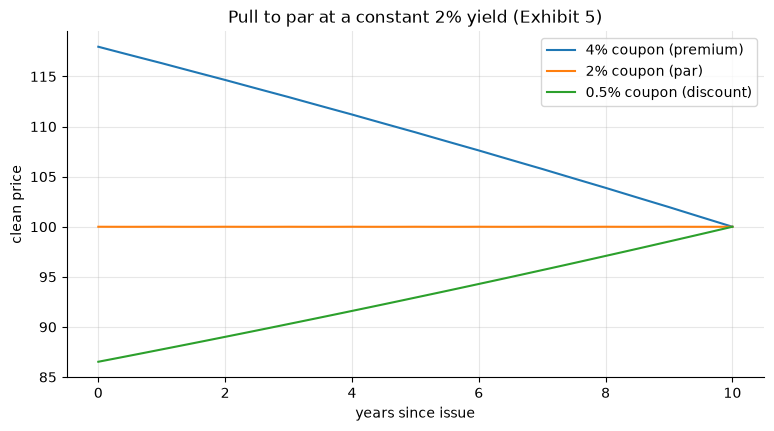

{0.04: (117.97, 109.43), 0.005: (86.53, 92.93)} | par bond's lowest clean price: 99.995


In [8]:
# Exhibit 5: pull to par, clean prices monthly at a constant 2% yield
def clean_price(t, c, y=0.02, n=10, M=100.0):
    if t >= n: return M
    full = sum((c * M + (M if j == n else 0.0)) * (1 + y) ** -(j - t) for j in range(1, n + 1) if j > t + 1e-12)
    return full - c * M * (t - int(t + 1e-12))

ts = np.arange(121) / 12
fig, ax = plt.subplots()
for c, lab in ((0.04, "4% coupon (premium)"), (0.02, "2% coupon (par)"), (0.005, "0.5% coupon (discount)")):
    ax.plot(ts, [clean_price(t, c) for t in ts], label=lab)
ax.set_xlabel("years since issue"); ax.set_ylabel("clean price"); ax.set_title("Pull to par at a constant 2% yield (Exhibit 5)"); ax.legend(); plt.show()
print({c: (round(clean_price(0, c), 2), round(clean_price(5, c), 2)) for c in (0.04, 0.005)},
      "| par bond's lowest clean price:", round(min(clean_price(t, 0.02) for t in ts), 4))

## Part 4 — Loan amortization

Level payment: $\mathrm{PMT}=B_0i/(1-(1+i)^{-n})$ (6.16), balance $B_t=\mathrm{PMT}\,a_{n-t,i}$ (6.17), principal $Q_t=\mathrm{PMT}\,v^{n-t+1}$ (6.18). Equal principal: total interest $iB_0(n+1)/2$ (6.19). The schedules below are built row by row from the balance recurrence (6.4), so they test the closed forms. Total interest is undiscounted; the last cell values each schedule's payments at a discount rate.

In [9]:
def schedule(B0, apr, years, grace_years=0, method="level"):
    i, n = apr / 12, years * 12
    m = grace_years * 12
    pmt, Q = amort_payment(B0, i, n - m), B0 / (n - m)
    rows, B = [], B0
    for t in range(1, n + 1):
        I = B * i
        prin = 0.0 if t <= m else (pmt - I if method == "level" else Q)
        B -= prin
        rows.append((t, I + prin, I, prin, B))
    return pl.DataFrame(rows, schema=["t", "payment", "interest", "principal", "balance"], orient="row")

lvl = schedule(10_000_000, 0.022, 30)
eqp = schedule(10_000_000, 0.022, 30, method="equal")
grc = schedule(10_000_000, 0.022, 30, grace_years=3)
i = 0.022 / 12
print(f"payment {lvl['payment'][0]:,.2f} (unrounded {lvl['payment'][0]:.6f});  balance after 60 {lvl['balance'][59]:,.2f}"
      f" (prospective {annuity_pv(lvl['payment'][0], i, 300):,.2f})")
print(f"interest in 5 years {lvl['interest'][:60].sum():,.0f}  principal {lvl['principal'][:60].sum():,.0f}")
print(f"principal ratio {lvl['principal'][1] / lvl['principal'][0]:.7f} = 1 + i;  doubling time {math.log(2)/math.log(1+i):.1f} months")
summary = pl.DataFrame({
    "method": ["level payment", "equal principal", "level after 3-year grace"],
    "first": [s["payment"][0] for s in (lvl, eqp, grc)],
    "payment 37": [s["payment"][36] for s in (lvl, eqp, grc)],
    "last": [s["payment"][-1] for s in (lvl, eqp, grc)],
    "total interest": [s["interest"].sum() for s in (lvl, eqp, grc)]})
print(f"equal principal: {summary['total interest'][0] - summary['total interest'][1]:,.2f} less interest;"
      f"  grace period: {summary['total interest'][2] - summary['total interest'][0]:,.2f} more (both undiscounted)")
print("equal-principal payment falls below the level payment at month", eqp.filter(pl.col("payment") < lvl["payment"][0])["t"][0])
lvl.filter(pl.col("t").is_in([1, 2, 120, 180, 240, 359, 360]))   # Exhibit 6, first table

payment 37,970.08 (unrounded 37970.084143);  balance after 60 8,755,754.89 (prospective 8,755,754.89)
interest in 5 years 1,033,960  principal 1,244,245
principal ratio 1.0018333 = 1 + i;  doubling time 378.4 months
equal principal: 360,063.62 less interest;  grace period: 261,984.38 more (both undiscounted)
equal-principal payment falls below the level payment at month 161


t,payment,interest,principal,balance
i64,f64,f64,f64,f64
1,37970.0841,18333.3333,19636.7508,9980363.2492
2,37970.0841,18297.3326,19672.7515,9960690.4977
120,37970.0841,13550.8825,24419.2017,7366971.2382
180,37970.0841,10714.2099,27255.8742,5816858.6195
240,37970.0841,7548.0134,30422.0707,4086676.1525
359,37970.0841,138.8417,37831.2424,37900.5997
360,37970.0841,69.4844,37900.5997,0.0000


In [10]:
summary.with_columns(pl.col("total interest").round(2))   # Exhibit 6, second table

method,first,payment 37,last,total interest
str,f64,f64,f64,f64
"""level payment""",37970.0841,37970.0841,37970.0841,3669230.2900
"""equal principal""",46111.1111,44277.7778,27828.7037,3309166.6700
"""level after 3-year grace""",18333.3333,40960.5391,40960.5391,3931214.6700


In [11]:
# Total interest is not a price: discount each schedule's payments. At the loan rate every schedule is worth the
# principal; repaying faster pays off only when the discount rate (your alternative return) is below the loan rate.
def pv_payments(s, j):
    return s.select((pl.col("payment") * (1 + j) ** (-pl.col("t"))).sum()).item()

rates = [0.022, 0.017, 0.03]                  # the loan rate, a deposit rate (illustrative) and 3%, each monthly at r/12
pv = pl.DataFrame({"discount rate (a year)": rates,
                   **{name: [pv_payments(s, r / 12) for r in rates]
                      for name, s in (("level", lvl), ("equal principal", eqp), ("3-year grace", grc))}})
pv.with_columns((pl.col("equal principal") - pl.col("level")).round(2).alias("equal - level"),
                (pl.col("3-year grace") - pl.col("level")).round(2).alias("grace - level"))

discount rate (a year),level,equal principal,3-year grace,equal - level,grace - level
f64,f64,f64,f64,f64,f64
0.0220,10000000.0000,10000000.0000,10000000.0000,0.0000,-0.0000
0.0170,10701872.4426,10638479.4827,10751124.0114,-63392.9600,49251.5700
0.0300,9006100.7736,9090291.7148,8937335.3179,84190.9400,-68765.4600


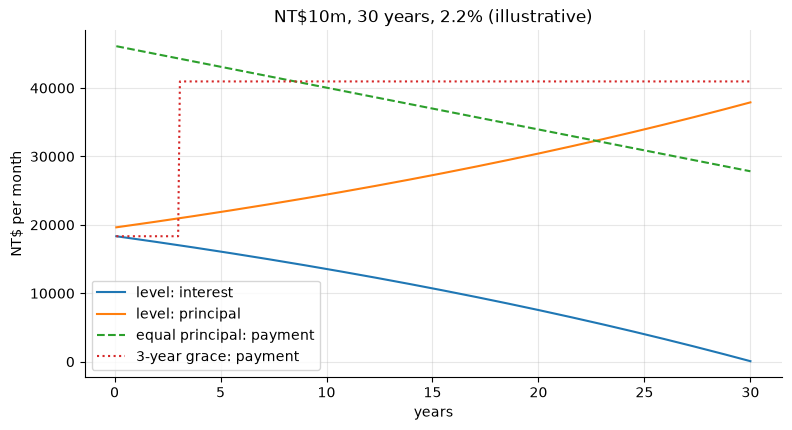

5%: doubling 166.7 months; crossover at payment 195
KC6: 26252.24 2798273


In [12]:
fig, ax = plt.subplots()
yrs = lvl["t"] / 12
ax.plot(yrs, lvl["interest"], label="level: interest"); ax.plot(yrs, lvl["principal"], label="level: principal")
ax.plot(yrs, eqp["payment"], "--", label="equal principal: payment"); ax.plot(yrs, grc["payment"], ":", label="3-year grace: payment")
ax.set_xlabel("years"); ax.set_ylabel("NT$ per month"); ax.set_title("NT$10m, 30 years, 2.2% (illustrative)"); ax.legend(); plt.show()
# 5% comparison: principal overtakes interest only when the remaining term is below the doubling time
i5 = 0.05 / 12
print("5%: doubling", round(math.log(2) / math.log(1 + i5), 1), "months; crossover at payment",
      schedule(10_000_000, 0.05, 30).filter(pl.col("principal") > pl.col("interest"))["t"][0])
print("KC6:", round(amort_payment(5_000_000, 0.002, 240), 2), round(schedule(5_000_000, 0.024, 20)["balance"][119]))

## Part 5 — Forward rates and covered interest parity

$(1+z_{t_2})^{t_2}=(1+z_{t_1})^{t_1}(1+y_{t_1,t_2})^{t_2-t_1}$ (6.20) and $F=S(1+i_{\text{TWD}}\tau)/(1+i_{\text{USD}}\tau)$ (6.21).

In [13]:
curve = pl.DataFrame({"t": [1, 2, 3, 4, 5], "z": [0.015, 0.017, 0.0185, 0.0195, 0.0205]}).with_columns(
    ((1 + pl.col("z")) ** (-pl.col("t"))).alias("discount factor"))
curve = curve.with_columns((pl.col("discount factor").shift(1).fill_null(1.0) / pl.col("discount factor") - 1).alias("y(t-1,t)"))
y25 = ((1.0205**5 / 1.017**2) ** (1 / 3)) - 1
P_curve = (3 * curve["discount factor"]).sum() + 100 * curve["discount factor"][-1]
y_curve, _ = bisect(lambda y: bond_price(y, 0.03, 5) - P_curve, 0.0, 0.1)
print(f"y(2,5) = {y25:.4%} (log approximation {(5*0.0205 - 2*0.017)/3:.4%});  5y 3% bond {P_curve:.4f}, YTM {y_curve:.4%}")
S, iT, iU = 30.00, 0.016, 0.040
F = S * (1 + iT) / (1 + iU)
print(f"USD/TWD forward {F:.4f}  points {F - S:+.4f}  first-order {S*(1 + iT - iU):.4f}  arbitrage at 29.50: {(29.50 - F) * (1 + iU):.4f} TWD")
curve   # Exhibit 7

y(2,5) = 2.2840% (log approximation 2.2833%);  5y 3% bond 104.5346, YTM 2.0369%
USD/TWD forward 29.3077  points -0.6923  first-order 29.2800  arbitrage at 29.50: 0.2000 TWD


t,z,discount factor,"y(t-1,t)"
i64,f64,f64,f64
1,0.0150,0.9852,0.0150
2,0.0170,0.9668,0.0190
3,0.0185,0.9465,0.0215
4,0.0195,0.9257,0.0225
5,0.0205,0.9035,0.0245


## Part 6 — The TX basis through the 2025 dividend season

Futures: regular-session daily settlement prices; the expiring contract shows settlement 0.0 on its expiry day (the final settlement price is not in the file) and is dropped. Expiry is the third Wednesday of the delivery month. The realized dividend yield over $[t,T]$ is $q_{\text{real}}\tau=\ln(\mathrm{TR}_T/\mathrm{TR}_t)-\ln(S_T/S_t)$, counted on ex-dates. On an ex-date $\mathrm{TR}/S$ rises by $1/(1-\delta)$, so $\delta=1-e^{-\Delta}$ for a daily excess log return $\Delta$, and the index points removed are $\delta$ times the previous close. The decomposition (6.25) is
$F-S=S(e^{r_f\tau}-1)-Se^{r_f\tau}(1-e^{-q_{\text{real}}\tau})+\varepsilon$; its dividend term applies the realized yield to the index on the pricing date and carries it to expiry.

In [14]:
RF = 0.02
idx = (pl.read_csv(DATA / "TAIEX_2025.csv").select("date", pl.col("close").alias("S"), "spread")
         .join(pl.read_csv(DATA / "TAIEX_TR_2025.csv").rename({"price": "TR"}), on="date", how="full", coalesce=True).sort("date"))
assert idx.null_count().sum_horizontal().item() == 0
spread_err = idx.select((pl.col("S") - pl.col("S").shift(1) - pl.col("spread")).abs().max()).item()
idx = idx.with_columns(((pl.col("TR") / pl.col("TR").shift(1)).log() - (pl.col("S") / pl.col("S").shift(1)).log()).alias("dq"))
print(f"{idx.height} days; max |close - prev - spread| = {spread_err:.1e}; min daily dq = {idx['dq'].min()*1e4:.4f} bp")

def third_wednesday(y, m):
    d = dt.date(y, m, 1)
    return d + dt.timedelta(days=(2 - d.weekday()) % 7 + 14)

tx = pl.read_csv(DATA / "TX__2025-04-01__2025-10-31.csv").with_columns(pl.col("contract_date").cast(pl.Utf8).alias("c"))
expiry = {c: third_wednesday(int(c[:4]), int(c[4:])).isoformat() for c in tx["c"].unique().to_list()}
print("rows with settlement 0 (expiry days):", tx.filter(pl.col("settlement_price") == 0).select("date", "c").rows())
d = (tx.filter(pl.col("settlement_price") > 0)
       .with_columns(pl.col("c").replace_strict(expiry).alias("expiry"), pl.col("settlement_price").alias("F"))
       .join(idx.select("date", "S", "TR"), on="date", how="left")
       .join(idx.select(pl.col("date").alias("expiry"), pl.col("S").alias("S_T"), pl.col("TR").alias("TR_T")), on="expiry", how="left")
       .with_columns(((pl.col("expiry").str.to_date() - pl.col("date").str.to_date()).dt.total_days()).alias("days"))
       .with_columns((pl.col("days") / 365).alias("tau")))
d = (d.with_columns(
        (pl.col("F") - pl.col("S")).alias("basis"),
        (RF * pl.col("tau") - (pl.col("F") / pl.col("S")).log()).alias("qtau_imp"),
        ((pl.col("TR_T") / pl.col("TR")).log() - (pl.col("S_T") / pl.col("S")).log()).alias("qtau_real"))
      .with_columns(
        (pl.col("S") * ((RF * pl.col("tau")).exp() - 1)).alias("carry"),
        (pl.col("S") * (RF * pl.col("tau")).exp() * (1 - (-pl.col("qtau_real")).exp())).alias("dividends"),
        (pl.col("S") * ((RF * pl.col("tau") - pl.col("qtau_real")).exp() - 1)).alias("fair_basis"))
      .with_columns(
        (pl.col("basis") - pl.col("fair_basis")).alias("residual"),
        ((pl.col("qtau_real") + (pl.col("F") / pl.col("S")).log()) / pl.col("tau")).alias("r_implied"))
      .sort(["date", "days"]))
print(d.height, "contract-days")

244 days; max |close - prev - spread| = 3.5e-12; min daily dq = -0.0044 bp


rows with settlement 0 (expiry days): [('2025-04-16', '202504'), ('2025-05-21', '202505'), ('2025-06-18', '202506'), ('2025-07-16', '202507'), ('2025-08-20', '202508'), ('2025-09-17', '202509'), ('2025-10-15', '202510')]
869 contract-days


In [15]:
# Exhibit 1: the curve on 27 June 2025, with volumes (back months trade a few lots a day)
snap = d.filter(pl.col("date") == pl.lit("2025-06-27"))
snap.select("c", "expiry", "days", "volume", "F", pl.col("basis").round(2), "qtau_imp", (pl.col("close") - pl.col("F")).alias("last trade - settlement"))

c,expiry,days,volume,F,basis,qtau_imp,last trade - settlement
str,str,i64,i64,f64,f64,f64,f64
"""202507""","""2025-07-16""",19,60785,22122.0000,-458.0800,0.0215,-1.0000
"""202508""","""2025-08-20""",54,1436,21948.0000,-632.0800,0.0314,0.0000
"""202509""","""2025-09-17""",82,22,21834.0000,-746.0800,0.0381,-34.0000
"""202512""","""2025-12-17""",173,49,21700.0000,-880.0800,0.0492,0.0000
"""202603""","""2026-03-18""",264,9,21607.0000,-973.0800,0.0585,-16.0000
"""202606""","""2026-06-17""",355,2,21493.0000,-1087.0800,0.0688,-54.0000


2025 total 2.93%; June-September 2.44% (83%); July 1.08%


11 Dec 2025: TR/S up 14.21 bp (log), dq = 0.00142149; delta 14.205 bp of the 10 Dec close 28,400.73 = 40.34 points (press estimate 40.34)


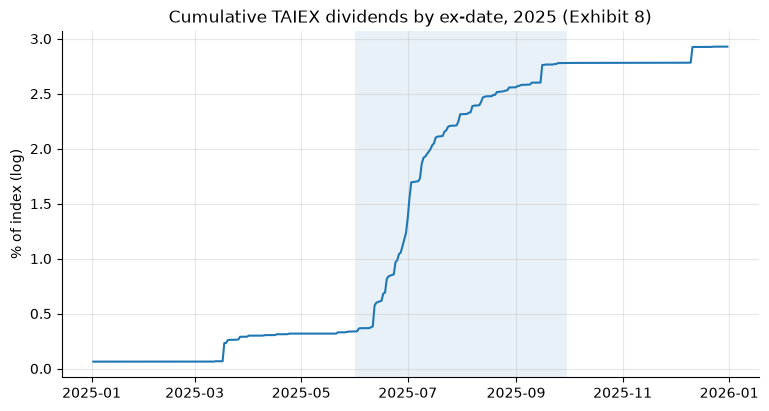

In [16]:
# Exhibit 8: dividends by ex-date in calendar 2025
q2025 = math.log(idx["TR"][-1] / idx["TR"][0]) - math.log(idx["S"][-1] / idx["S"][0])
by_month = (idx.drop_nulls("dq").group_by(pl.col("date").str.slice(5, 2).cast(pl.Int32).alias("month"))
               .agg(pl.col("dq").sum()).sort("month"))
jun_sep = by_month.filter(pl.col("month").is_between(6, 9))["dq"].sum()
dq11 = idx.filter(pl.col("date") == pl.lit("2025-12-11"))["dq"][0]
s_prev = idx.filter(pl.col("date") == pl.lit("2025-12-10"))["S"][0]
delta11 = 1 - math.exp(-dq11)                     # TR/S rises by 1/(1 - delta) on an ex-date
print(f"2025 total {q2025:.2%}; June-September {jun_sep:.2%} ({jun_sep/q2025:.0%}); July {by_month['dq'][6]:.2%}")
print(f"11 Dec 2025: TR/S up {dq11*1e4:.2f} bp (log), dq = {dq11:.8f}; delta {delta11*1e4:.3f} bp of the 10 Dec close {s_prev:,.2f}"
      f" = {delta11*s_prev:.2f} points (press estimate 40.34)")
cum = idx.drop_nulls("dq").with_columns(pl.col("dq").cum_sum().alias("cum"), pl.col("date").str.to_date())
fig, ax = plt.subplots()
ax.plot(cum["date"], cum["cum"] * 100); ax.axvspan(dt.date(2025, 6, 1), dt.date(2025, 9, 30), alpha=0.1)
ax.set_ylabel("% of index (log)"); ax.set_title("Cumulative TAIEX dividends by ex-date, 2025 (Exhibit 8)"); plt.show()

In [17]:
# Exhibit 9: decomposition on 27 June 2025 (residual = basis - carry + dividends)
decomp = snap.filter(pl.col("qtau_real").is_not_null()).select(
    "c", *[pl.col(x).round(2) for x in ("basis", "carry", "dividends", "residual")], "qtau_imp",
    (pl.col("qtau_real") * 100).round(5).alias("qtau_real (%)"), "r_implied")
check = decomp.select((pl.col("carry") - pl.col("dividends") + pl.col("residual") - pl.col("basis")).abs().max()).item()
print("adds up at 2 decimals:", check < 1e-9, "| realized qtau (%), as printed in the exhibit:", decomp["qtau_real (%)"].to_list())
with pl.Config(float_precision=5):   # five decimals, so realized qtau (%) shows as printed in the exhibit
    print(decomp)

adds up at 2 decimals: True | realized qtau (%), as printed in the exhibit: [0.99299, 1.43449, 1.70655, 1.86971]
shape: (4, 8)
┌────────┬────────────┬───────────┬───────────┬────────────┬──────────┬───────────────┬───────────┐
│ c      ┆ basis      ┆ carry     ┆ dividends ┆ residual   ┆ qtau_imp ┆ qtau_real (%) ┆ r_implied │
│ ---    ┆ ---        ┆ ---       ┆ ---       ┆ ---        ┆ ---      ┆ ---           ┆ ---       │
│ str    ┆ f64        ┆ f64       ┆ f64       ┆ f64        ┆ f64      ┆ f64           ┆ f64       │
╞════════╪════════════╪═══════════╪═══════════╪════════════╪══════════╪═══════════════╪═══════════╡
│ 202507 ┆ -458.08000 ┆ 23.52000  ┆ 223.34000 ┆ -258.26000 ┆ 0.02154  ┆ 0.99299       ┆ -0.20297  │
│ 202508 ┆ -632.08000 ┆ 66.91000  ┆ 322.55000 ┆ -376.44000 ┆ 0.03135  ┆ 1.43449       ┆ -0.09495  │
│ 202509 ┆ -746.08000 ┆ 101.68000 ┆ 383.79000 ┆ -463.97000 ┆ 0.03809  ┆ 1.70655       ┆ -0.07360  │
│ 202512 ┆ -880.08000 ┆ 215.06000 ┆ 422.24000 ┆ -672.90000 ┆ 0.04924  ┆ 1

In [18]:
# Index points actually removed on the ex-dates, against the yield measure of (6.25)
ix = idx.with_columns(pl.col("S").shift(1).alias("S_prev"))
for x in snap.filter(pl.col("qtau_real").is_not_null()).sort("days").iter_rows(named=True):
    w = (ix.filter((pl.col("date") > pl.lit("2025-06-27")) & (pl.col("date") <= pl.lit(x["expiry"])))
           .with_columns(((1 - (-pl.col("dq")).exp()) * pl.col("S_prev")).alias("pts"),
                         ((pl.lit(x["expiry"]).str.to_date() - pl.col("date").str.to_date()).dt.total_days() / 365).alias("t_left")))
    fv = (w["pts"] * (RF * w["t_left"]).exp()).sum()
    print(f"{x['c']}: points removed {w['pts'].sum():.1f}, carried to expiry {fv:.1f}; (6.25) dividends {x['dividends']:.1f};"
          f" residual measured in points {x['basis'] - x['carry'] + fv:.1f} vs {x['residual']:.1f}")
print(f"TAIEX 17 Dec / 27 Jun: {idx.filter(pl.col('date') == pl.lit('2025-12-17'))['S'][0] / snap['S'][0]:.3f}")

202507: points removed 223.4, carried to expiry 223.5; (6.25) dividends 223.3; residual measured in points -258.1 vs -258.3
202508: points removed 327.2, carried to expiry 327.9; (6.25) dividends 322.6; residual measured in points -371.1 vs -376.4
202509: points removed 394.9, carried to expiry 396.1; (6.25) dividends 383.8; residual measured in points -451.7 vs -464.0
202512: points removed 440.7, carried to expiry 444.0; (6.25) dividends 422.2; residual measured in points -651.2 vs -672.9
TAIEX 17 Dec / 27 Jun: 1.219


In [19]:
# Is 27 June typical? Ranks over the sample, multi-day figures, calendar spreads and volumes
dec = d.filter(pl.col("c") == "202512").sort("date")
near = d.group_by("date", maintain_order=True).first().sort("date")
rank = lambda frame, col: frame.sort(col)["date"].to_list().index("2025-06-27") + 1
print(f"27 June among {dec.height} sessions (1 = most negative): December basis {rank(dec, 'basis')}, residual {rank(dec, 'residual')},"
      f" implied financing rate {rank(dec, 'r_implied')}; near-month residual {rank(near, 'residual')}"
      f" (lowest {near.sort('residual').select('date', pl.col('residual').round(1)).row(0)})")
w = dec.filter(pl.col("date").is_between(pl.lit("2025-06-23"), pl.lit("2025-07-03")))
print(f"23 June-3 July ({w.height} sessions): mean December residual {w['residual'].mean():.1f};"
      f" December residual negative on {(dec['residual'] < 0).sum()} of {dec.height} sessions")
print("December on 30 June (residual, implied financing rate, implied qtau at r_f = 0):",
      dec.filter(pl.col("date") == pl.lit("2025-06-30")).select(pl.col("residual").round(1), "r_implied", (-(pl.col("F") / pl.col("S")).log())).row(0))
jj = (dec.filter(pl.col("date").is_between(pl.lit("2025-06-01"), pl.lit("2025-07-31")))
         .with_columns((-(pl.col("F") / pl.col("S")).log()).alias("qtau_r0"),
                       (pl.col("F") - pl.col("S") * (-pl.col("qtau_real")).exp()).alias("resid_r0")))
print(f"June-July ({jj.height} sessions): residual at r_f = 0 negative on {(jj['resid_r0'] < 0).sum()};"
      f" zero-rate implied qtau above the 2025 total on {(jj['qtau_r0'] > q2025).sum()} (last {jj.filter(pl.col('qtau_r0') > q2025)['date'].max()})")

sn = snap.sort("days")
for a, b in zip(sn.iter_rows(named=True), list(sn.iter_rows(named=True))[1:4]):
    dtau = b["tau"] - a["tau"]
    imp = RF * dtau - math.log(b["F"] / a["F"])
    real = math.log(b["TR_T"] / a["TR_T"]) - math.log(b["S_T"] / a["S_T"])
    print(f"{a['c']} -> {b['c']}: implied forward dividends {imp:.2%}, went ex {real:.2%}  (volumes {a['volume']:,} and {b['volume']:,})")

traded = dec.filter(pl.col("volume") > 0).with_columns((pl.col("close") - pl.col("F")).alias("gap"))
print(f"December: median {dec['volume'].median()} lots a day, no trades on {(dec['volume'] == 0).sum()} days;"
      f" largest |last trade - settlement| (date, lots, points): {traded.sort(pl.col('gap').abs(), descending=True).select('date', 'volume', 'gap').row(0)}")
print("June 2026 contract on 30 June (lots, settlement):", d.filter((pl.col("c") == "202606") & (pl.col("date") == pl.lit("2025-06-30"))).select("volume", "F").row(0),
      f"| near month: median {near['volume'].median():,.0f} lots a day")
pos = d.sort(["date", "days"]).with_columns(pl.col("days").rank("ordinal").over("date").alias("pos"))
print("median lots a day by position on the curve (1 = nearest):", pos.group_by("pos").agg(pl.col("volume").median()).sort("pos").rows())

27 June among 146 sessions (1 = most negative): December basis 1, residual 1, implied financing rate 1; near-month residual 2 (lowest ('2025-04-08', -298.1))
23 June-3 July (9 sessions): mean December residual -461.1; December residual negative on 131 of 146 sessions
December on 30 June (residual, implied financing rate, implied qtau at r_f = 0): (-370.5, -0.016318954554118373, 0.024517169835645513)
June-July (44 sessions): residual at r_f = 0 negative on 43; zero-rate implied qtau above the 2025 total on 17 (last 2025-06-27)
202507 -> 202508: implied forward dividends 0.98%, went ex 0.44%  (volumes 60,785 and 1,436)
202508 -> 202509: implied forward dividends 0.67%, went ex 0.27%  (volumes 1,436 and 22)
202509 -> 202512: implied forward dividends 1.11%, went ex 0.16%  (volumes 22 and 49)
December: median 14.5 lots a day, no trades on 4 days; largest |last trade - settlement| (date, lots, points): ('2025-07-11', 1, -256.0)
June 2026 contract on 30 June (lots, settlement): (0, 21501.0) 

In [20]:
# Exhibit 10: near-month contract by calendar month (whole index points add up)
monthly = (near.group_by(pl.col("date").str.slice(5, 2).cast(pl.Int32).alias("month"))
            .agg(pl.len().alias("trading days"), pl.col("days").mean().round(1).alias("days to expiry"),
                 *[pl.col(x).mean().round(0) for x in ("basis", "carry", "dividends", "residual")],
                 pl.col("qtau_imp").mean(), pl.col("qtau_real").mean())
            .sort("month"))
same = near.with_columns(pl.col("basis").diff().alias("db"), (pl.col("c") == pl.col("c").shift(1)).alias("same")).filter(pl.col("same"))
print(f"sample sd (divisor n - 1) of daily changes in the near-month basis: {same['db'].std():.1f} points ({same.height} pairs)")
print("adds up:", monthly.select((pl.col("carry") - pl.col("dividends") + pl.col("residual") - pl.col("basis")).abs().max()).item() == 0)
monthly

sample sd (divisor n - 1) of daily changes in the near-month basis: 83.4 points (138 pairs)


adds up: True


month,trading days,days to expiry,basis,carry,dividends,residual,qtau_imp,qtau_real
i32,u32,f64,f64,f64,f64,f64,f64,f64
4,20,18.8000,-65.0000,20.0000,1.0000,-84.0000,0.0044,0.0000
5,20,14.7000,-78.0000,17.0000,27.0000,-68.0000,0.0045,0.0013
6,21,14.8000,-192.0000,18.0000,135.0000,-75.0000,0.0095,0.0061
7,23,18.3000,-79.0000,23.0000,68.0000,-34.0000,0.0044,0.0030
8,21,14.9000,-33.0000,20.0000,34.0000,-19.0000,0.0022,0.0014
9,21,14.7000,0.0000,20.0000,24.0000,4.0000,0.0008,0.0010
10,20,19.2000,67.0000,29.0000,0.0000,38.0000,-0.0014,0.0000


shape: (7, 5)
┌───────┬───────────┬────────────┬───────────┬───────────┐
│ month ┆ basis     ┆ fair_basis ┆ residual  ┆ r_implied │
│ ---   ┆ ---       ┆ ---        ┆ ---       ┆ ---       │
│ i32   ┆ f64       ┆ f64        ┆ f64       ┆ f64       │
╞═══════╪═══════════╪════════════╪═══════════╪═══════════╡
│ 4     ┆ -439.6000 ┆ -248.1000  ┆ -191.5000 ┆ 0.0048    │
│ 5     ┆ -710.2000 ┆ -301.1000  ┆ -409.2000 ┆ -0.0135   │
│ 6     ┆ -723.5000 ┆ -273.1000  ┆ -450.4000 ┆ -0.0215   │
│ 7     ┆ -409.8000 ┆ -22.3000   ┆ -387.5000 ┆ -0.0202   │
│ 8     ┆ -164.7000 ┆ 48.7000    ┆ -213.4000 ┆ -0.0060   │
│ 9     ┆ -24.3000  ┆ 66.3000    ┆ -90.5000  ┆ 0.0064    │
│ 10    ┆ 83.0000   ┆ 52.1000    ┆ 30.9000   ┆ 0.0282    │
└───────┴───────────┴────────────┴───────────┴───────────┘


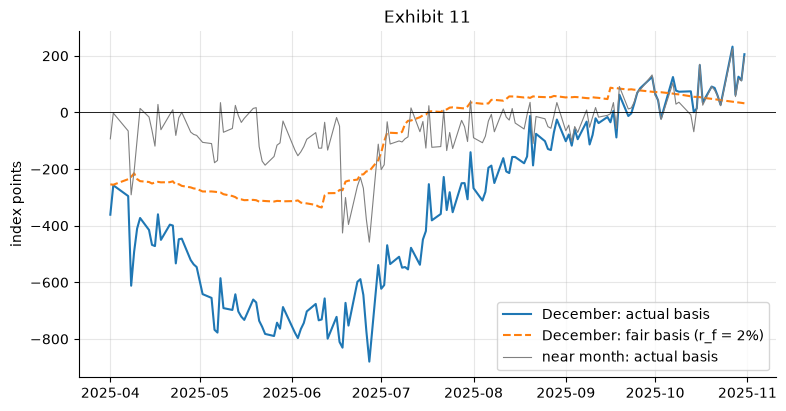

In [21]:
# December contract by month, and Exhibit 11
print(dec.group_by(pl.col("date").str.slice(5, 2).cast(pl.Int32).alias("month"))
         .agg(pl.col("basis").mean().round(1), pl.col("fair_basis").mean().round(1), pl.col("residual").mean().round(1),
              pl.col("r_implied").mean()).sort("month"))
fig, ax = plt.subplots()
x = dec["date"].str.to_date()
ax.plot(x, dec["basis"], label="December: actual basis"); ax.plot(x, dec["fair_basis"], "--", label="December: fair basis (r_f = 2%)")
ax.plot(near["date"].str.to_date(), near["basis"], color="grey", lw=0.8, label="near month: actual basis")
ax.axhline(0, color="black", lw=0.6); ax.set_ylabel("index points"); ax.set_title("Exhibit 11"); ax.legend(); plt.show()

2025-04-01 [('202504', 15, -93.17), ('202505', 50, -77.17), ('202506', 78, -94.17), ('202509', 169, -357.17), ('202512', 260, -361.17), ('202603', 351, -347.17)]
2025-06-27 [('202507', 19, -458.08), ('202508', 54, -632.08), ('202509', 82, -746.08), ('202512', 173, -880.08), ('202603', 264, -973.08), ('202606', 355, -1087.08)]
2025-10-31 [('202511', 19, 196.65), ('202512', 47, 205.65), ('202601', 82, 236.65), ('202603', 138, 242.65), ('202606', 229, 216.65), ('202609', 320, -21.35)]


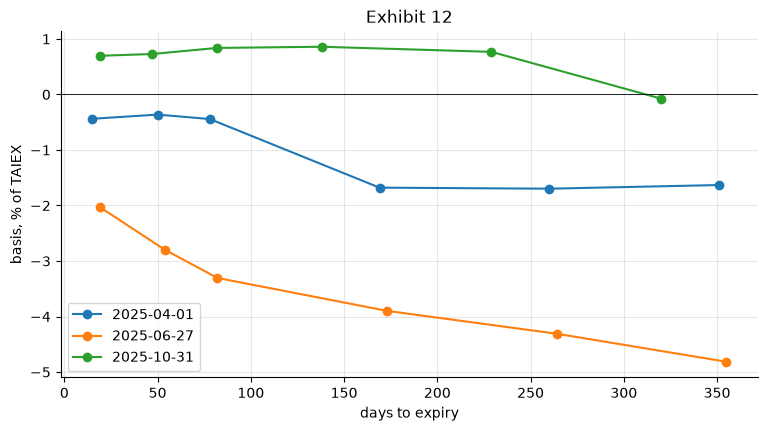

shape: (2, 5)
┌────────────┬────────────┬────────────┬───────────┬───────────┐
│ date       ┆ S          ┆ F          ┆ basis     ┆ residual  │
│ ---        ┆ ---        ┆ ---        ┆ ---       ┆ ---       │
│ str        ┆ f64        ┆ f64        ┆ f64       ┆ f64       │
╞════════════╪════════════╪════════════╪═══════════╪═══════════╡
│ 2025-06-27 ┆ 22580.0800 ┆ 22122.0000 ┆ -458.0800 ┆ -258.2600 │
│ 2025-06-30 ┆ 22256.0200 ┆ 22144.0000 ┆ -112.0200 ┆ 49.2500   │
└────────────┴────────────┴────────────┴───────────┴───────────┘
30 June: TAIEX -324.06 (-1.44%), total-return index -1.26%; ex-dividend 40.2 points; basis jump net of it 305.9; 1 July +297.7
shape: (4, 6)
┌────────────┬────────────┬────────────┬────────────┬────────────┬───────────┐
│ date       ┆ open       ┆ max        ┆ min        ┆ close      ┆ spread    │
│ ---        ┆ ---        ┆ ---        ┆ ---        ┆ ---        ┆ ---       │
│ str        ┆ f64        ┆ f64        ┆ f64        ┆ f64        ┆ f64       │
╞════════

In [22]:
# Exhibit 12: three term structures; then the numbers of the pitfall on annualizing a noisy basis
fig, ax = plt.subplots()
for day in ("2025-04-01", "2025-06-27", "2025-10-31"):
    cv = d.filter(pl.col("date") == pl.lit(day))
    ax.plot(cv["days"], cv["basis"] / cv["S"] * 100, marker="o", label=day)
    print(day, cv.select("c", "days", pl.col("basis").round(2)).rows())
ax.axhline(0, color="black", lw=0.6); ax.set_xlabel("days to expiry"); ax.set_ylabel("basis, % of TAIEX"); ax.set_title("Exhibit 12"); ax.legend(); plt.show()
j = d.filter(pl.col("c") == "202507").filter(pl.col("date").is_in(["2025-06-27", "2025-06-30"])).sort("date")
print(j.select("date", "S", "F", "basis", pl.col("residual").round(2)))
i27, i30, i01 = (idx.filter(pl.col("date") == pl.lit(x)).row(0, named=True) for x in ("2025-06-27", "2025-06-30", "2025-07-01"))
delta30 = 1 - math.exp(-i30["dq"])
print(f"30 June: TAIEX {i30['S'] - i27['S']:+.2f} ({i30['S']/i27['S'] - 1:+.2%}), total-return index {i30['TR']/i27['TR'] - 1:+.2%};"
      f" ex-dividend {delta30*i27['S']:.1f} points; basis jump net of it {j['basis'][1] - j['basis'][0] - delta30*i27['S']:.1f}; 1 July {i01['S'] - i30['S']:+.1f}")
print(pl.read_csv(DATA / "TAIEX_OHLC__2025-06-26__2025-07-01.csv"))
print(near.with_columns((pl.col("qtau_imp") / pl.col("tau")).alias("q_ann")).sort("q_ann", descending=True).head(1).select("date", "days", "basis", "q_ann"))

In [23]:
# Example 9: the December contract on 27 June 2025, and the sensitivity of the implied yield to r_f
x = snap.filter(pl.col("c") == "202512").row(0, named=True)
print(f"tau {x['tau']:.5f}  qtau {x['qtau_imp']:.2%}  annual {x['qtau_imp']/x['tau']:.2%}  PV of dividends {x['S'] - x['F']*math.exp(-RF*x['tau']):.1f} points")
print(f"F_fair {x['S'] + x['fair_basis']:.2f}  residual {x['residual']:.2f} ({x['residual']/x['S']:.2%})  implied financing rate {x['r_implied']:.2%}")
pl.DataFrame({"r_f": [0.0, 0.01, 0.02, 0.03]}).with_columns(
    (pl.col("r_f") * x["tau"] - math.log(x["F"] / x["S"])).alias("implied qtau"),
    (x["F"] - x["S"] * (pl.col("r_f") * x["tau"] - x["qtau_real"]).exp()).alias("residual"))

tau 0.47397  qtau 4.92%  annual 10.39%  PV of dividends 1084.8 points
F_fair 22372.90  residual -672.90 (-2.98%)  implied financing rate -4.44%


r_f,implied qtau,residual
f64,f64,f64
0.0000,0.0398,-461.8199
0.0100,0.0445,-567.1102
0.0200,0.0492,-672.9007
0.0300,0.0540,-779.1939


## Part 7 — Practice problems (computational) and an extension

In [24]:
print("PP2 ", f"{annuity_fv(5000, 0.0015, 120):,.2f}", f"{annuity_pv(5000, 0.0015, 120):,.2f}")
print("PP3 ", f"due {annuity_pv(2000, 0.025, 15, True):,.2f}  ordinary {annuity_pv(2000, 0.025, 15):,.2f}")
print("PP4 ", f"gamma {(0.08*80 - 3.2)/(80 + 3.2):.3%}  k {3.2*1.04/80 + 0.04:.2%}")
print("PP5 ", f"forward P/E {0.6/(0.09 - 0.05):.2f}  trailing {0.6*1.05/(0.09 - 0.05):.2f}")
print("PP6 ", f"{bond_price(0.0175, 0.0225, 7):.4f}")
lg7 = []; y7, _ = bisect(lambda y: bond_price(y, 0.02, 3) - 98.0, 0.02, 0.04, tol=1e-9, log=lg7)
print("PP7 ", [(f"{m:.2%}", round(f, 4)) for _, _, _, m, f in lg7[:3]], f"YTM {y7:.4%}")
s8 = schedule(8_000_000, 0.021, 20); pmt8 = s8["payment"][0]
print("PP8 ", f"{pmt8:,.2f} ({pmt8:.6f})", f"{s8['balance'][95]:,.2f}", f"{s8['interest'][96]:,.2f}", f"{s8['principal'][96]:,.2f}",
      f"total interest {s8['interest'].sum():,.2f}")
s9 = schedule(8_000_000, 0.021, 20, method="equal")
print("PP9 ", f"{s9['payment'][0]:,.2f}", f"{s9['payment'][-1]:,.2f}", f"{s9['interest'].sum():,.2f}", f"vs {s8['interest'].sum():,.2f};",
      "PV of equal principal minus level at 2.1%, 1.7%, 3%:", [round(pv_payments(s9, r / 12) - pv_payments(s8, r / 12), 2) for r in (0.021, 0.017, 0.03)])
print("PP10", f"{31.20*(1 + 0.015*0.25)/(1 + 0.042*0.25):.4f}")
Ff = 23_000 * math.exp(0.02*0.2 - 0.012)
print("PP11", f"fair {Ff:.2f}  qtau {0.004 - math.log(22_600/23_000):.4%}  residual {22_600 - Ff:.2f}  r_impl {(0.012 + math.log(22_600/23_000))/0.2:.2%}")

PP2  656,853.04 548,723.77
PP3  due 25,381.82  ordinary 24,762.76
PP4  gamma 3.846%  k 8.16%
PP5  forward P/E 15.00  trailing 15.75
PP6  103.2673
PP7  [('3.00%', -0.8286), ('2.50%', 0.572), ('2.75%', -0.1317)] YTM 2.7030%
PP8  40,850.63 (40850.632422) 5,195,828.36 9,092.70 31,757.93 total interest 1,804,151.78
PP9  47,333.33 33,391.67 1,687,000.00 vs 1,804,151.78; PV of equal principal minus level at 2.1%, 1.7%, 3%: [-0.0, -18811.34, 37294.26]
PP10 30.9916
PP11 fair 22816.73  qtau 2.1544%  residual -216.73  r_impl -2.77%


In [25]:
# PP12: the September 2025 contract by month (the expiry-day row, settlement 0, was dropped with the others above).
# No implied financing rate: a mean of daily annualized rates is dominated by the last sessions before expiry.
(d.filter(pl.col("c") == "202509")
  .group_by(pl.col("date").str.slice(5, 2).cast(pl.Int32).alias("month"))
  .agg(pl.len().alias("n"), pl.col("date").max().alias("last session"),
       *[pl.col(x).mean().round(0) for x in ("basis", "carry", "dividends", "residual")])
  .sort("month"))

month,n,last session,basis,carry,dividends,residual
i32,u32,str,f64,f64,f64,f64
4,20,"""2025-04-30""",-439.0000,165.0000,478.0000,-126.0000
5,20,"""2025-05-29""",-637.0000,145.0000,516.0000,-266.0000
6,21,"""2025-06-30""",-619.0000,113.0000,459.0000,-273.0000
7,23,"""2025-07-31""",-253.0000,79.0000,178.0000,-154.0000
8,21,"""2025-08-29""",-73.0000,42.0000,74.0000,-41.0000
9,12,"""2025-09-16""",-34.0000,12.0000,40.0000,-6.0000


### Extension: was 2025 unusual?

Repeat Part 6 for the 2024 dividend season. Fetch `TaiwanFuturesDaily` (TX, regular session `trading_session == "position"`, single-month contracts only), `TaiwanStockPrice` (TAIEX) and `TaiwanStockTotalReturnIndex` (TAIEX) for April–December 2024, rebuild Exhibit 9, Exhibit 10 and Exhibit 11, and compare the residuals over several days rather than one. A residual that is negative every summer would point to a structural discount (weak reverse-arbitrage bound); one that appears only in 2025 would point to the hedging pressure after the April tariff shock. Check the volumes too: a back-month residual built on a few lots says little. The optional helper below refreshes data with your own token (`FINMIND_TOKEN`) through the standard library's `urllib`; queries are limited in size, so it fetches month by month.

In [26]:
import json
import os
import urllib.parse
import urllib.request

def finmind(dataset, data_id, start, end):
    # optional live refresh (needs FINMIND_TOKEN); month-by-month windows stay under FinMind's row limit
    token, out, d0 = os.environ["FINMIND_TOKEN"], [], dt.date.fromisoformat(start)
    while d0 <= dt.date.fromisoformat(end):
        d1 = min(dt.date(d0.year + (d0.month == 12), d0.month % 12 + 1, 1) - dt.timedelta(days=1), dt.date.fromisoformat(end))
        q = urllib.parse.urlencode({"dataset": dataset, "data_id": data_id, "start_date": d0.isoformat(),
                                    "end_date": d1.isoformat(), "token": token})
        req = urllib.request.Request("https://api.finmindtrade.com/api/v4/data?" + q,
                                     headers={"Authorization": f"Bearer {token}", "User-Agent": "calculus-to-kelly"})
        with urllib.request.urlopen(req, timeout=60) as r:
            out.extend(json.loads(r.read().decode("utf-8")).get("data", []))
        d0 = d1 + dt.timedelta(days=1)
    return pl.DataFrame(out)

# uncomment to run (regular session, single-month contracts):
# tx24 = finmind("TaiwanFuturesDaily", "TX", "2024-04-01", "2024-12-31").filter(
#     (pl.col("trading_session") == pl.lit("position")) & pl.col("contract_date").str.contains(r"^\d{6}$"))